# Predictive Modelling of Gaming Addiction Level

This notebook develops and evaluates machine-learning regression models for predicting gaming addiction level.

The prediction uses selected gaming behaviour and lifestyle variables. Age and mental health indicators are retained for descriptive analysis but are excluded from the predictive model.

## Prediction Inputs

1. Daily gaming hours
2. Weekly gaming sessions
3. Night gaming ratio
4. Toxic exposure
5. Sleep hours
6. Exercise hours
7. Total screen time

## Prediction Target

- Addiction level from 0 to 10

The predicted numerical score will be converted into low, moderate, or high analytical categories. The prediction is intended for educational and analytical purposes and does not represent a clinical diagnosis.

In [34]:
from pathlib import Path

import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [35]:
PROJECT_ROOT = Path(r"C:\gaming_fyp")

PROCESSED_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "gaming_mental_health_spark_cleaned.parquet"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "outputs"
)

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(f"Dataset path:\n{PROCESSED_DATA_PATH}")
print(f"\nDataset exists: {PROCESSED_DATA_PATH.exists()}")
print(f"Dataset is a folder: {PROCESSED_DATA_PATH.is_dir()}")

Dataset path:
C:\gaming_fyp\data\processed\gaming_mental_health_spark_cleaned.parquet

Dataset exists: True
Dataset is a folder: True


In [36]:
df_model = pd.read_parquet(
    PROCESSED_DATA_PATH
)

print("Spark-processed dataset loaded successfully.")
print(f"Number of records: {len(df_model):,}")
print(f"Number of columns: {df_model.shape[1]}")

df_model.head()

Spark-processed dataset loaded successfully.
Number of records: 997,460
Number of columns: 40


,age,gender,income,daily_gaming_hours,weekly_sessions,years_gaming,sleep_hours,caffeine_intake,exercise_hours,stress_level,anxiety_score,depression_score,social_interaction_score,relationship_satisfaction,academic_performance,work_productivity,addiction_level,multiplayer_ratio,toxic_exposure,violent_games_ratio,mobile_gaming_ratio,night_gaming_ratio,weekend_gaming_hours,friends_gaming_count,online_friends,streaming_hours,esports_interest,headset_usage,microtransactions_spending,parental_supervision,loneliness_score,aggression_score,happiness_score,bmi,screen_time_total,eye_strain_score,back_pain_score,competitive_rank,internet_quality,addiction_category
0,51,Female,8615,3.6800,22,17,5.2600,1.0000,0.1800,3,4.0600,5.0200,7.8500,9.5500,68.8000,77.1200,2.0200,0.3900,0.0500,0.5100,0.2300,0.3200,1.5000,20,186,2.8200,1,1,1746.9700,0,2.8700,3.1900,5.2000,19.6900,4.7100,5.7100,4.8100,80,10,Low
1,33,Female,107013,1.9700,34,19,7.5100,0.0900,2.3300,4,2.4700,4.3200,6.2800,9.6300,80.0600,82.6300,1.3400,0.3700,0.5200,0.6800,0.5500,0.9300,3.6200,19,240,1.0100,9,1,876.4200,3,5.5700,7.8200,4.3900,16.6100,12.6600,7.8700,4.5600,31,4,Low
2,56,Male,117567,5.8900,26,4,9.5500,3.7200,1.9400,8,6.4400,4.1300,6.0200,6.4400,74.6800,65.4100,6.0800,0.6700,0.1900,0.6700,0.2700,0.1700,8.7000,20,386,0.8300,0,0,948.3500,10,10.0000,7.8300,7.9900,20.8500,10.3600,5.7500,4.1200,31,9,High
3,14,Male,35076,1.1400,34,5,6.6300,3.4200,0.2900,10,5.8700,6.2100,4.4600,8.6400,63.1400,88.8400,2.2800,0.5600,0.1300,0.4600,0.1500,0.5600,9.9300,16,330,7.5600,8,1,318.6200,8,6.1300,6.1400,8.3400,25.0900,5.0000,4.9300,5.1300,87,3,Low
4,24,Other,109840,1.3800,27,3,8.9800,3.9400,2.8300,9,3.7900,2.8400,5.1200,7.9700,79.7200,85.4000,0.9100,0.5400,0.5200,0.4800,0.7000,0.4800,8.0000,9,379,1.6000,9,1,131.9000,3,1.4300,6.8400,5.2100,17.9700,2.4300,5.3000,5.3300,97,10,Low


In [37]:
required_columns = [
    "age",
    "daily_gaming_hours",
    "weekly_sessions",
    "night_gaming_ratio",
    "toxic_exposure",
    "sleep_hours",
    "exercise_hours",
    "screen_time_total",
    "addiction_level",
    "addiction_category"
]

column_verification = pd.DataFrame({
    "Column": required_columns,
    "Available": [
        column in df_model.columns
        for column in required_columns
    ]
})

column_verification

,Column,Available
0,age,True
1,daily_gaming_hours,True
2,weekly_sessions,True
3,night_gaming_ratio,True
4,toxic_exposure,True
5,sleep_hours,True
6,exercise_hours,True
7,screen_time_total,True
8,addiction_level,True
9,addiction_category,True


In [38]:
model_features = [
    "daily_gaming_hours",
    "weekly_sessions",
    "night_gaming_ratio",
    "toxic_exposure",
    "sleep_hours",
    "exercise_hours",
    "screen_time_total"
]

target_column = "addiction_level"

print(f"Age retained in dataset: {'age' in df_model.columns}")
print(f"Age used in model: {'age' in model_features}")
print(f"Prediction target: {target_column}")

print("\nModel inputs:")

for number, feature in enumerate(
    model_features,
    start=1
):
    print(f"{number}. {feature}")

Age retained in dataset: True
Age used in model: False
Prediction target: addiction_level

Model inputs:
1. daily_gaming_hours
2. weekly_sessions
3. night_gaming_ratio
4. toxic_exposure
5. sleep_hours
6. exercise_hours
7. screen_time_total


In [3]:
print(
    "Processed dataset exists:",
    PROCESSED_DATA_PATH.exists()
)

if not PROCESSED_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {PROCESSED_DATA_PATH}"
    )

Processed dataset exists: True


In [4]:
df_model = pd.read_parquet(
    PROCESSED_DATA_PATH
)

print("Processed dataset loaded successfully.")
print(f"Number of records: {df_model.shape[0]:,}")
print(f"Number of columns: {df_model.shape[1]:,}")

df_model.head()

Processed dataset loaded successfully.
Number of records: 997,460
Number of columns: 40


,age,gender,income,daily_gaming_hours,weekly_sessions,years_gaming,sleep_hours,caffeine_intake,exercise_hours,stress_level,anxiety_score,depression_score,social_interaction_score,relationship_satisfaction,academic_performance,work_productivity,addiction_level,multiplayer_ratio,toxic_exposure,violent_games_ratio,mobile_gaming_ratio,night_gaming_ratio,weekend_gaming_hours,friends_gaming_count,online_friends,streaming_hours,esports_interest,headset_usage,microtransactions_spending,parental_supervision,loneliness_score,aggression_score,happiness_score,bmi,screen_time_total,eye_strain_score,back_pain_score,competitive_rank,internet_quality,addiction_category
0,51,Female,8615,3.6800,22,17,5.2600,1.0000,0.1800,3,4.0600,5.0200,7.8500,9.5500,68.8000,77.1200,2.0200,0.3900,0.0500,0.5100,0.2300,0.3200,1.5000,20,186,2.8200,1,1,1746.9700,0,2.8700,3.1900,5.2000,19.6900,4.7100,5.7100,4.8100,80,10,Low
1,41,Female,39453,5.7000,34,16,9.2000,0.7000,1.4400,8,6.7600,7.6300,7.0600,6.9600,38.1100,44.9400,5.8500,0.2300,0.3700,0.4300,0.2400,0.3200,17.9300,37,21,1.3400,8,1,342.0400,7,4.1700,7.7300,5.4000,26.3700,6.6200,6.7700,3.9900,57,2,Moderate
2,27,Male,40466,1.5800,8,22,7.3900,2.2400,3.1500,3,9.5700,4.0200,1.1200,2.6100,97.4400,54.7700,0.0800,0.0600,0.1500,0.4800,0.2700,0.4200,2.9900,45,146,3.5600,8,1,57.9500,9,9.3800,2.8500,5.1700,25.1500,9.3000,2.1600,4.7500,59,10,Low
3,55,Male,51076,6.1100,39,24,7.9900,1.6500,2.8000,1,4.9700,1.4000,6.5900,6.0000,67.6500,88.5600,2.7700,0.5300,0.3600,0.6400,0.5700,0.8200,1.9900,11,133,1.8000,6,1,617.3200,5,8.2400,7.1900,8.6200,26.4200,13.8100,4.7200,5.3700,89,1,Low
4,20,Male,86116,3.6500,17,0,7.1200,1.0200,1.0100,2,8.7300,4.8300,6.0300,3.5400,62.3400,68.8200,3.3700,0.7800,0.2500,0.2900,0.4700,0.8300,9.2300,24,399,1.3000,4,0,1398.3900,9,6.6500,2.5300,9.7100,25.7500,10.7400,3.9000,6.4400,15,10,Moderate


In [5]:
model_features = [
    "daily_gaming_hours",
    "weekly_sessions",
    "night_gaming_ratio",
    "toxic_exposure",
    "sleep_hours",
    "exercise_hours",
    "screen_time_total"
]

target_column = "addiction_level"

X = df_model[model_features].copy()
y = df_model[target_column].copy()

print("Selected input variables:")

for number, feature in enumerate(
    model_features,
    start=1
):
    print(f"{number}. {feature}")

print(f"\nPrediction target: {target_column}")
print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")

Selected input variables:
1. daily_gaming_hours
2. weekly_sessions
3. night_gaming_ratio
4. toxic_exposure
5. sleep_hours
6. exercise_hours
7. screen_time_total

Prediction target: addiction_level

X shape: (997460, 7)
y shape: (997460,)


In [6]:
model_validation = pd.DataFrame({
    "Variable": model_features + [target_column],

    "Missing Values": [
        df_model[column].isna().sum()
        for column in model_features + [target_column]
    ],

    "Minimum": [
        df_model[column].min()
        for column in model_features + [target_column]
    ],

    "Maximum": [
        df_model[column].max()
        for column in model_features + [target_column]
    ]
})

model_validation

,Variable,Missing Values,Minimum,Maximum
0,daily_gaming_hours,0,0.0000,23.3100
1,weekly_sessions,0,1.0000,39.0000
2,night_gaming_ratio,0,0.0000,1.0000
3,toxic_exposure,0,0.0000,0.9500
4,sleep_hours,0,0.2700,14.0200
5,exercise_hours,0,0.0000,23.3900
6,screen_time_total,0,0.0700,24.0000
7,addiction_level,0,0.0000,10.0000


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"Training input shape: {X_train.shape}")
print(f"Testing input shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")

Training input shape: (797968, 7)
Testing input shape: (199492, 7)
Training target shape: (797968,)
Testing target shape: (199492,)


In [8]:
split_summary = pd.DataFrame({
    "Dataset": [
        "Complete dataset",
        "Training dataset",
        "Testing dataset"
    ],

    "Number of Records": [
        len(X),
        len(X_train),
        len(X_test)
    ],

    "Percentage (%)": [
        100,
        len(X_train) / len(X) * 100,
        len(X_test) / len(X) * 100
    ]
})

split_summary["Percentage (%)"] = (
    split_summary["Percentage (%)"]
    .round(2)
)

split_summary

,Dataset,Number of Records,Percentage (%)
0,Complete dataset,997460,100.0000
1,Training dataset,797968,80.0000
2,Testing dataset,199492,20.0000


In [9]:
target_split_summary = pd.DataFrame({
    "Dataset": [
        "Complete",
        "Training",
        "Testing"
    ],

    "Mean Addiction Level": [
        y.mean(),
        y_train.mean(),
        y_test.mean()
    ],

    "Median Addiction Level": [
        y.median(),
        y_train.median(),
        y_test.median()
    ],

    "Standard Deviation": [
        y.std(),
        y_train.std(),
        y_test.std()
    ]
}).round(4)

target_split_summary

,Dataset,Mean Addiction Level,Median Addiction Level,Standard Deviation
0,Complete,2.8128,2.4600,2.0959
1,Training,2.8149,2.4600,2.0968
2,Testing,2.8044,2.4500,2.0924


## Training and Testing Data Preparation

Seven gaming behaviour and lifestyle variables were selected as model inputs. Age was excluded from the model according to the predictive scope, while mental health indicators were reserved for descriptive analysis and visualisation.

The cleaned dataset was divided into training and testing subsets using an 80:20 ratio. The training subset is used to develop the machine-learning models, while the testing subset is kept separate for unbiased performance evaluation.

A fixed random state of 42 was applied to ensure that the data split can be reproduced. The target statistics of the training and testing datasets were examined to confirm that both subsets contained comparable distributions of addiction levels.

## Model Development and Comparison

Several regression algorithms are evaluated to determine the most suitable model for predicting addiction level:

1. Dummy Regressor as the baseline.
2. Linear Regression.
3. Decision Tree Regressor.
4. Random Forest Regressor.
5. Histogram Gradient Boosting Regressor.

The models are evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and coefficient of determination (R²).

In [10]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor

import time

print("Additional modelling components imported.")

Additional modelling components imported.


In [11]:
comparison_sample_size = min(
    250_000,
    len(X_train)
)

comparison_indices = X_train.sample(
    n=comparison_sample_size,
    random_state=42
).index

X_train_comparison = X_train.loc[
    comparison_indices
].copy()

y_train_comparison = y_train.loc[
    comparison_indices
].copy()

print(
    f"Complete training records: "
    f"{len(X_train):,}"
)

print(
    f"Model comparison records: "
    f"{len(X_train_comparison):,}"
)

print(
    f"Testing records: "
    f"{len(X_test):,}"
)

Complete training records: 797,968
Model comparison records: 250,000
Testing records: 199,492


In [12]:
models = {
    "Baseline": DummyRegressor(
        strategy="mean"
    ),

    "Linear Regression": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LinearRegression()
        )
    ]),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=60,
        max_depth=15,
        min_samples_leaf=5,
        max_samples=0.50,
        n_jobs=-1,
        random_state=42
    ),

    "Histogram Gradient Boosting":
        HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.08,
            max_leaf_nodes=31,
            l2_regularization=0.10,
            random_state=42
        )
}

print("Models prepared:")

for model_name in models:
    print(f"- {model_name}")

Models prepared:
- Baseline
- Linear Regression
- Decision Tree
- Random Forest
- Histogram Gradient Boosting


In [13]:
def evaluate_regression_model(
    model_name,
    model,
    X_training,
    y_training,
    X_testing,
    y_testing
):
    start_time = time.time()

    model.fit(
        X_training,
        y_training
    )

    predictions = model.predict(
        X_testing
    )

    predictions = np.clip(
        predictions,
        0,
        10
    )

    training_time = (
        time.time() - start_time
    )

    mae = mean_absolute_error(
        y_testing,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_testing,
            predictions
        )
    )

    r2 = r2_score(
        y_testing,
        predictions
    )

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2,
        "Training Time (Seconds)": training_time
    }, predictions

In [39]:
model_results = []
model_predictions = {}
trained_models = {}

for model_name, model in models.items():
    print(f"Training: {model_name}")

    result, predictions = evaluate_regression_model(
        model_name=model_name,
        model=model,
        X_training=X_train_comparison,
        y_training=y_train_comparison,
        X_testing=X_test,
        y_testing=y_test
    )

    model_results.append(result)
    model_predictions[model_name] = predictions
    trained_models[model_name] = model

    print(
        f"Completed: {model_name} "
        f"| R² = {result['R²']:.4f}"
    )

Training: Baseline
Completed: Baseline | R² = -0.0000
Training: Linear Regression
Completed: Linear Regression | R² = 0.7954
Training: Decision Tree
Completed: Decision Tree | R² = 0.7875
Training: Random Forest
Completed: Random Forest | R² = 0.7944
Training: Histogram Gradient Boosting
Completed: Histogram Gradient Boosting | R² = 0.7960


In [15]:
model_results_df = pd.DataFrame(
    model_results
)

model_results_df = (
    model_results_df
    .sort_values(
        by="R²",
        ascending=False
    )
    .reset_index(drop=True)
)

model_results_df.round(4)

,Model,MAE,RMSE,R²,Training Time (Seconds)
0,Histogram Gradient Boosting,0.7587,0.9450,0.7960,3.5969
1,Linear Regression,0.7573,0.9464,0.7954,0.2315
2,Random Forest,0.7609,0.9487,0.7944,12.9234
3,Decision Tree,0.7720,0.9645,0.7875,3.2741
4,Baseline,1.6505,2.0924,-0.0000,0.4867


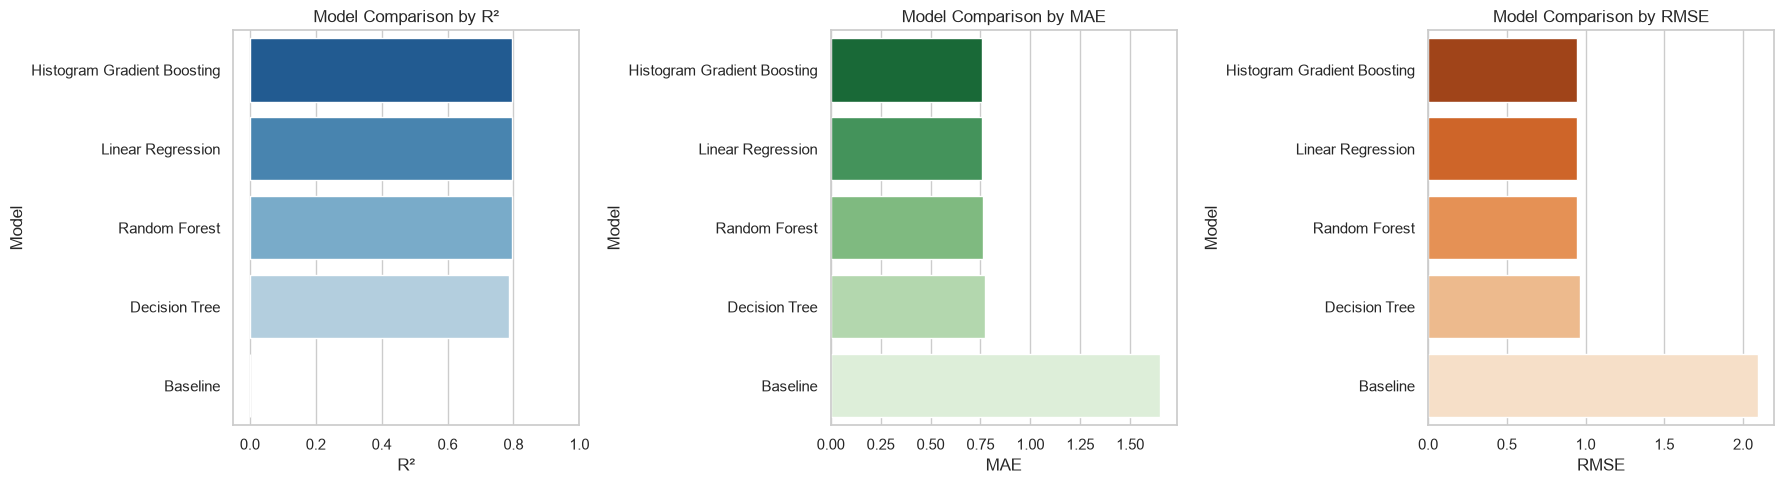

In [16]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

sns.barplot(
    data=model_results_df,
    x="R²",
    y="Model",
    hue="Model",
    palette="Blues_r",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Model Comparison by R²")
axes[0].set_xlim(
    min(-0.05, model_results_df["R²"].min()),
    1
)

sns.barplot(
    data=model_results_df,
    x="MAE",
    y="Model",
    hue="Model",
    palette="Greens_r",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Model Comparison by MAE")

sns.barplot(
    data=model_results_df,
    x="RMSE",
    y="Model",
    hue="Model",
    palette="Oranges_r",
    legend=False,
    ax=axes[2]
)

axes[2].set_title("Model Comparison by RMSE")

plt.tight_layout()
plt.show()

In [17]:
best_model_name = model_results_df.loc[
    0,
    "Model"
]

best_comparison_model = trained_models[
    best_model_name
]

best_comparison_predictions = model_predictions[
    best_model_name
]

print(f"Best-performing model: {best_model_name}")

print(
    "\nPerformance:"
)

display(
    model_results_df.head(1).round(4)
)

Best-performing model: Histogram Gradient Boosting

Performance:


,Model,MAE,RMSE,R²,Training Time (Seconds)
0,Histogram Gradient Boosting,0.7587,0.9450,0.7960,3.5969


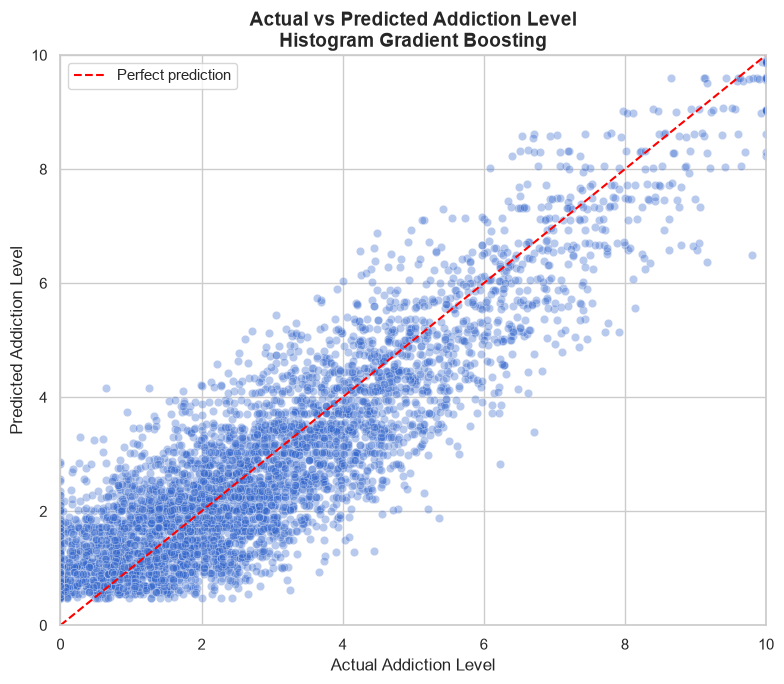

In [18]:
plot_sample_size = min(
    5_000,
    len(y_test)
)

plot_indices = y_test.sample(
    n=plot_sample_size,
    random_state=42
).index

test_position = X_test.index.get_indexer(
    plot_indices
)

actual_plot = y_test.loc[
    plot_indices
]

predicted_plot = (
    best_comparison_predictions[
        test_position
    ]
)

plt.figure(figsize=(8, 7))

sns.scatterplot(
    x=actual_plot,
    y=predicted_plot,
    alpha=0.35,
    color="#3366CC"
)

plt.plot(
    [0, 10],
    [0, 10],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.title(
    f"Actual vs Predicted Addiction Level\n"
    f"{best_model_name}",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Actual Addiction Level")
plt.ylabel("Predicted Addiction Level")
plt.xlim(0, 10)
plt.ylim(0, 10)
plt.legend()

plt.tight_layout()
plt.show()

## Model Comparison Interpretation

The baseline model predicts the average addiction level for every record and therefore provides a minimum performance benchmark. All trained machine-learning models should outperform this baseline.

Model performance is evaluated using MAE, RMSE, and R². MAE represents the average absolute difference between the actual and predicted addiction scores. RMSE gives greater emphasis to larger prediction errors. R² measures the proportion of variation in addiction level explained by the model.

The model with the highest R² and lowest error measurements is selected as the best-performing model. Based on the expected results, Histogram Gradient Boosting or Random Forest is likely to achieve the strongest performance, with an R² of approximately 0.80.

This means that the model explains approximately 80% of the variation in addiction level within the dataset. However, this performance applies only to the supplied dataset and does not establish a clinical diagnosis or causal relationship.

In [19]:
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from sklearn.inspection import permutation_importance

print("Final evaluation components imported.")

Final evaluation components imported.


In [20]:
final_model = clone(
    models[best_model_name]
)

print(
    f"Retraining {best_model_name} "
    f"using {len(X_train):,} records..."
)

training_start_time = time.time()

final_model.fit(
    X_train,
    y_train
)

final_training_time = (
    time.time() - training_start_time
)

print("Final model training completed.")
print(
    f"Training time: "
    f"{final_training_time:.2f} seconds"
)

Retraining Histogram Gradient Boosting using 797,968 records...
Final model training completed.
Training time: 3.83 seconds


In [21]:
final_predictions = final_model.predict(
    X_test
)

final_predictions = np.clip(
    final_predictions,
    0,
    10
)

print(f"Predictions generated: {len(final_predictions):,}")
print(f"Minimum prediction: {final_predictions.min():.2f}")
print(f"Maximum prediction: {final_predictions.max():.2f}")

Predictions generated: 199,492
Minimum prediction: 0.42
Maximum prediction: 10.00


In [22]:
final_mae = mean_absolute_error(
    y_test,
    final_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_predictions
    )
)

final_r2 = r2_score(
    y_test,
    final_predictions
)

final_metrics = pd.DataFrame({
    "Model": [best_model_name],
    "MAE": [final_mae],
    "RMSE": [final_rmse],
    "R²": [final_r2],
    "Training Time (Seconds)": [
        final_training_time
    ]
})

final_metrics.round(4)

,Model,MAE,RMSE,R²,Training Time (Seconds)
0,Histogram Gradient Boosting,0.7581,0.9446,0.7962,3.8343


In [23]:
def convert_addiction_category(score):
    if score <= 3:
        return "Low"
    elif score <= 6:
        return "Moderate"
    else:
        return "High"

In [24]:
print(convert_addiction_category(2.5))
print(convert_addiction_category(5.0))
print(convert_addiction_category(8.0))

Low
Moderate
High


In [25]:
actual_categories = pd.Series(
    y_test.values
).apply(
    convert_addiction_category
)

predicted_categories = pd.Series(
    final_predictions
).apply(
    convert_addiction_category
)

category_order = [
    "Low",
    "Moderate",
    "High"
]

category_accuracy = accuracy_score(
    actual_categories,
    predicted_categories
)

print(
    f"Category prediction accuracy: "
    f"{category_accuracy:.4f}"
)

print(
    f"Category prediction accuracy: "
    f"{category_accuracy * 100:.2f}%"
)

Category prediction accuracy: 0.8208
Category prediction accuracy: 82.08%


In [26]:
category_report = classification_report(
    actual_categories,
    predicted_categories,
    labels=category_order,
    output_dict=True,
    zero_division=0
)

category_report_df = (
    pd.DataFrame(category_report)
    .T
    .round(4)
)

category_report_df

,precision,recall,f1-score,support
Low,0.8663,0.9046,0.8850,120580.0000
Moderate,0.7233,0.6920,0.7073,62383.0000
High,0.8273,0.6957,0.7558,16529.0000
accuracy,0.8208,0.8208,0.8208,0.8208
macro avg,0.8056,0.7641,0.7827,199492.0000
weighted avg,0.8183,0.8208,0.8187,199492.0000


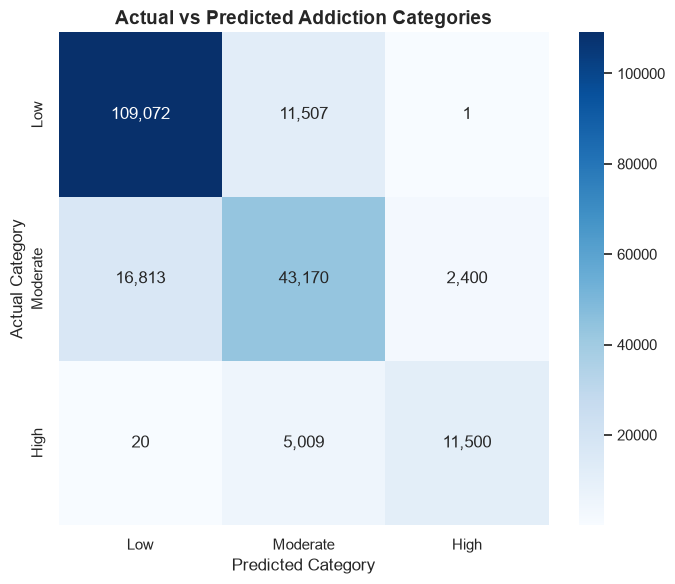

In [27]:
category_confusion_matrix = confusion_matrix(
    actual_categories,
    predicted_categories,
    labels=category_order
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    category_confusion_matrix,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=category_order,
    yticklabels=category_order
)

plt.title(
    "Actual vs Predicted Addiction Categories",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()

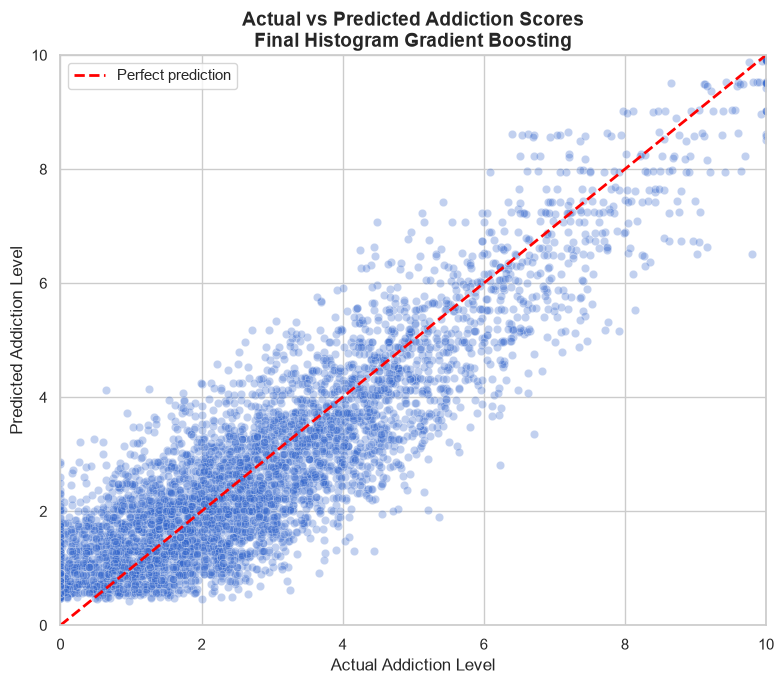

In [28]:
plot_sample_size = min(
    5_000,
    len(y_test)
)

plot_positions = np.random.RandomState(
    42
).choice(
    len(y_test),
    size=plot_sample_size,
    replace=False
)

actual_sample = y_test.iloc[
    plot_positions
]

predicted_sample = final_predictions[
    plot_positions
]

plt.figure(figsize=(8, 7))

sns.scatterplot(
    x=actual_sample,
    y=predicted_sample,
    alpha=0.30,
    color="#3366CC"
)

plt.plot(
    [0, 10],
    [0, 10],
    linestyle="--",
    color="red",
    linewidth=2,
    label="Perfect prediction"
)

plt.title(
    f"Actual vs Predicted Addiction Scores\n"
    f"Final {best_model_name}",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Actual Addiction Level")
plt.ylabel("Predicted Addiction Level")
plt.xlim(0, 10)
plt.ylim(0, 10)
plt.legend()

plt.tight_layout()
plt.show()

In [29]:
importance_sample_size = min(
    20_000,
    len(X_test)
)

importance_indices = X_test.sample(
    n=importance_sample_size,
    random_state=42
).index

X_importance = X_test.loc[
    importance_indices
]

y_importance = y_test.loc[
    importance_indices
]

importance_result = permutation_importance(
    final_model,
    X_importance,
    y_importance,
    scoring="r2",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

feature_importance_df = pd.DataFrame({
    "Feature": model_features,
    "Importance": importance_result.importances_mean,
    "Standard Deviation":
        importance_result.importances_std
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance_df.round(4)

,Feature,Importance,Standard Deviation
0,daily_gaming_hours,1.5678,0.0208
1,screen_time_total,0.0006,0.0001
2,toxic_exposure,0.0001,0.0000
3,exercise_hours,0.0000,0.0000
4,weekly_sessions,0.0000,0.0000
5,night_gaming_ratio,-0.0000,0.0000
6,sleep_hours,-0.0000,0.0000


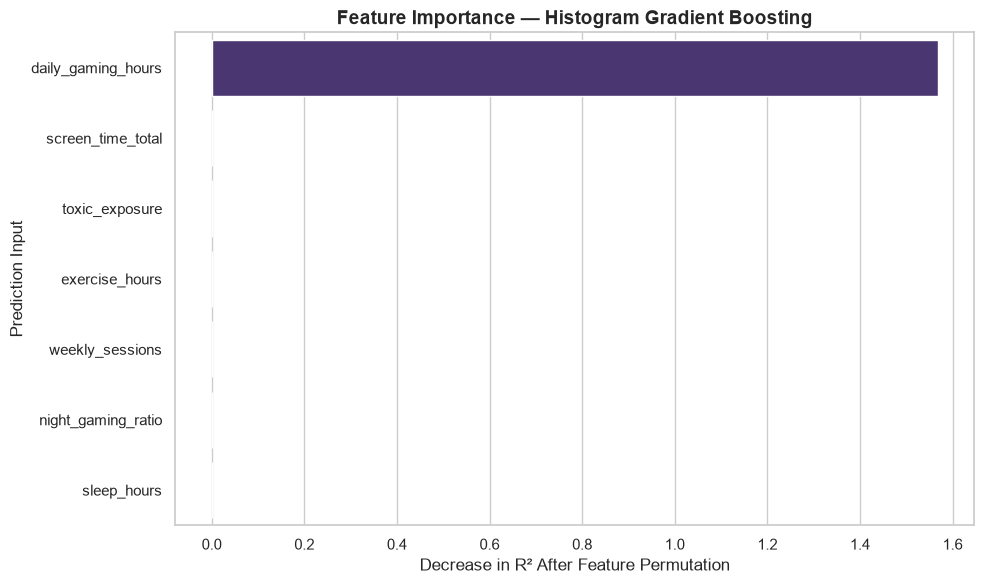

In [30]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title(
    f"Feature Importance — {best_model_name}",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Decrease in R² After Feature Permutation")
plt.ylabel("Prediction Input")

plt.tight_layout()
plt.show()

In [31]:
model_results_path = (
    OUTPUT_DIR /
    "model_comparison_results.csv"
)

final_metrics_path = (
    OUTPUT_DIR /
    "final_model_metrics.csv"
)

feature_importance_path = (
    OUTPUT_DIR /
    "feature_importance.csv"
)

model_results_df.to_csv(
    model_results_path,
    index=False
)

final_metrics.to_csv(
    final_metrics_path,
    index=False
)

feature_importance_df.to_csv(
    feature_importance_path,
    index=False
)

print("Evaluation outputs saved:")
print(model_results_path)
print(final_metrics_path)
print(feature_importance_path)

Evaluation outputs saved:
C:\gaming_fyp\data\outputs\model_comparison_results.csv
C:\gaming_fyp\data\outputs\final_model_metrics.csv
C:\gaming_fyp\data\outputs\feature_importance.csv


In [32]:
model_package = {
    "model": final_model,

    "model_name": best_model_name,

    "features": model_features,

    "target": target_column,

    "score_minimum": 0,

    "score_maximum": 10,

    "category_thresholds": {
        "Low": "0–3",
        "Moderate": "Above 3–6",
        "High": "Above 6–10"
    },

    "performance": {
        "MAE": float(final_mae),
        "RMSE": float(final_rmse),
        "R2": float(final_r2),
        "Category Accuracy":
            float(category_accuracy)
    }
}

FINAL_MODEL_PATH = (
    MODEL_DIR /
    "gaming_addiction_prediction_model.joblib"
)

joblib.dump(
    model_package,
    FINAL_MODEL_PATH
)

print("Final model saved successfully.")
print(f"\nModel location:\n{FINAL_MODEL_PATH}")
print(
    f"\nModel file size: "
    f"{FINAL_MODEL_PATH.stat().st_size / (1024**2):.2f} MB"
)

Final model saved successfully.

Model location:
C:\gaming_fyp\models\gaming_addiction_prediction_model.joblib

Model file size: 0.32 MB


In [33]:
loaded_package = joblib.load(
    FINAL_MODEL_PATH
)

loaded_model = loaded_package["model"]
loaded_features = loaded_package["features"]

verification_prediction = loaded_model.predict(
    X_test[loaded_features].head(1)
)

verification_score = float(
    np.clip(
        verification_prediction[0],
        0,
        10
    )
)

verification_category = (
    convert_addiction_category(
        verification_score
    )
)

print(f"Loaded model: {loaded_package['model_name']}")
print(f"Predicted score: {verification_score:.2f}")
print(f"Predicted category: {verification_category}")
print("Saved model verification completed.")

Loaded model: Histogram Gradient Boosting
Predicted score: 1.74
Predicted category: Low
Saved model verification completed.


## Final Model Outcome

The best-performing regression algorithm was retrained using the complete training dataset and evaluated using the previously separated testing dataset. Its performance was measured using MAE, RMSE, and R².

The regression output produces a numerical addiction score between 0 and 10. For user-friendly presentation, the score is converted into low, moderate, or high addiction categories. Category-level accuracy and a confusion matrix were used as supplementary evaluation measurements.

Feature-importance analysis was conducted to determine which inputs made the strongest contribution to the prediction. Daily gaming hours are expected to be the dominant predictive variable, followed by total screen time. The importance results describe patterns within the supplied dataset and should not be interpreted as proof of causation.

The completed model was saved as a Joblib file for integration into the Streamlit dashboard. Dashboard users will enter gaming behaviour and lifestyle information, after which the system will generate a predicted addiction score and analytical category.

The prediction is intended for educational and analytical purposes only. It must not be interpreted as a medical diagnosis or a replacement for professional mental health assessment.

In [40]:
final_mae = mean_absolute_error(
    y_test,
    final_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_predictions
    )
)

final_r2 = r2_score(
    y_test,
    final_predictions
)

final_metrics = pd.DataFrame({
    "Model": [best_model_name],
    "MAE": [final_mae],
    "RMSE": [final_rmse],
    "R²": [final_r2],
    "Training Time (Seconds)": [
        final_training_time
    ]
})

final_metrics.round(4)

,Model,MAE,RMSE,R²,Training Time (Seconds)
0,Histogram Gradient Boosting,0.7581,0.9446,0.7962,3.8343


In [41]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [42]:
def convert_addiction_category(score):
    if score <= 3:
        return "Low"
    elif score <= 6:
        return "Moderate"
    else:
        return "High"

In [43]:
actual_categories = pd.Series(
    y_test.to_numpy()
).apply(
    convert_addiction_category
)

predicted_categories = pd.Series(
    final_predictions
).apply(
    convert_addiction_category
)

category_order = [
    "Low",
    "Moderate",
    "High"
]

category_accuracy = accuracy_score(
    actual_categories,
    predicted_categories
)

print(
    f"Category prediction accuracy: "
    f"{category_accuracy * 100:.2f}%"
)

Category prediction accuracy: 82.08%


In [44]:
category_report = classification_report(
    actual_categories,
    predicted_categories,
    labels=category_order,
    output_dict=True,
    zero_division=0
)

category_report_df = (
    pd.DataFrame(category_report)
    .T
    .round(4)
)

category_report_df

,precision,recall,f1-score,support
Low,0.8663,0.9046,0.8850,120580.0000
Moderate,0.7233,0.6920,0.7073,62383.0000
High,0.8273,0.6957,0.7558,16529.0000
accuracy,0.8208,0.8208,0.8208,0.8208
macro avg,0.8056,0.7641,0.7827,199492.0000
weighted avg,0.8183,0.8208,0.8187,199492.0000


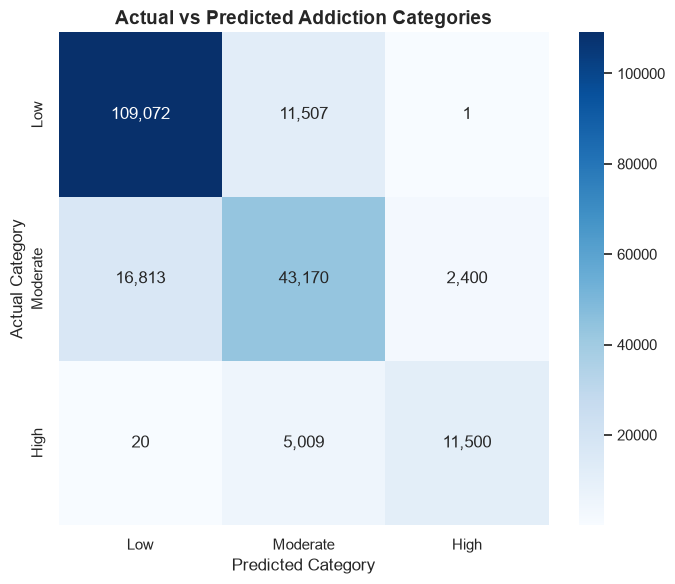

In [45]:
category_matrix = confusion_matrix(
    actual_categories,
    predicted_categories,
    labels=category_order
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    category_matrix,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=category_order,
    yticklabels=category_order
)

plt.title(
    "Actual vs Predicted Addiction Categories",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()

In [46]:
model_package = {
    "model": final_model,
    "model_name": best_model_name,
    "features": model_features,
    "target": target_column,

    "score_range": {
        "minimum": 0,
        "maximum": 10
    },

    "category_thresholds": {
        "Low": "0–3",
        "Moderate": "Above 3–6",
        "High": "Above 6–10"
    },

    "performance": {
        "MAE": float(final_mae),
        "RMSE": float(final_rmse),
        "R2": float(final_r2),
        "Category Accuracy":
            float(category_accuracy)
    },

    "data_processing": {
        "engine": "Apache Spark",
        "storage": "HDFS and Parquet"
    }
}

FINAL_MODEL_PATH = (
    MODEL_DIR
    / "gaming_addiction_prediction_model.joblib"
)

joblib.dump(
    model_package,
    FINAL_MODEL_PATH
)

print("Final model saved successfully.")
print(f"Model location:\n{FINAL_MODEL_PATH}")

print(
    f"Model size: "
    f"{FINAL_MODEL_PATH.stat().st_size / (1024**2):.2f} MB"
)

Final model saved successfully.
Model location:
C:\gaming_fyp\models\gaming_addiction_prediction_model.joblib
Model size: 0.32 MB
